<a href="https://colab.research.google.com/github/Shreya123714/Filters_Applied_on_Systems/blob/main/scipy_basedFilters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

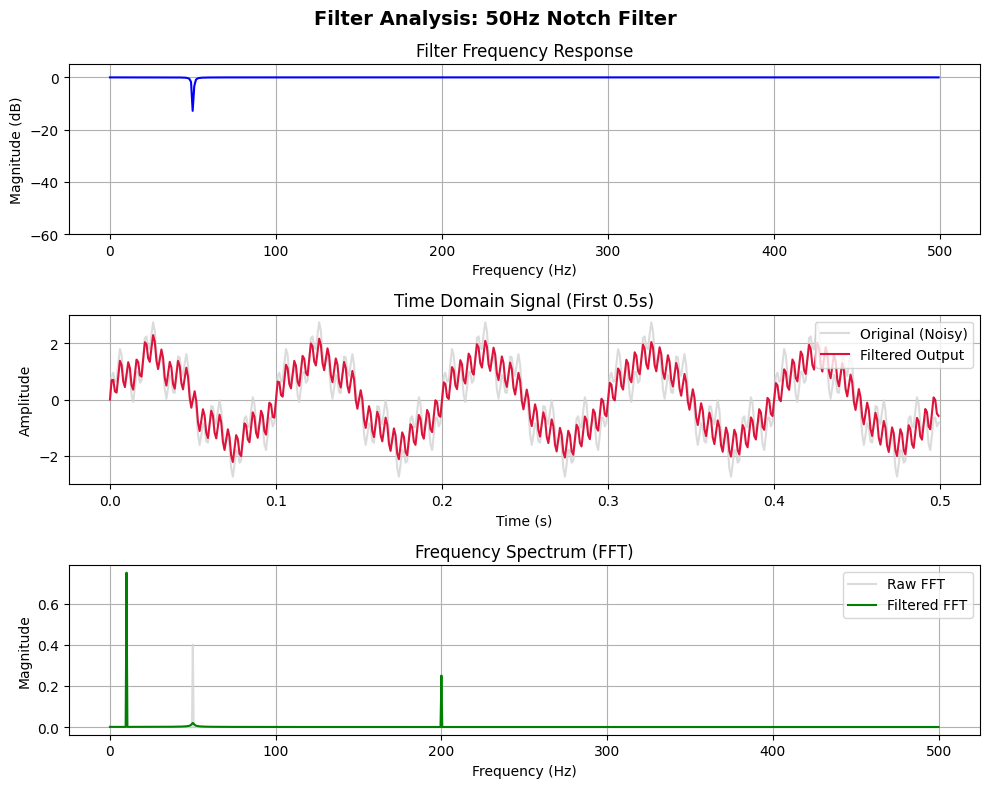

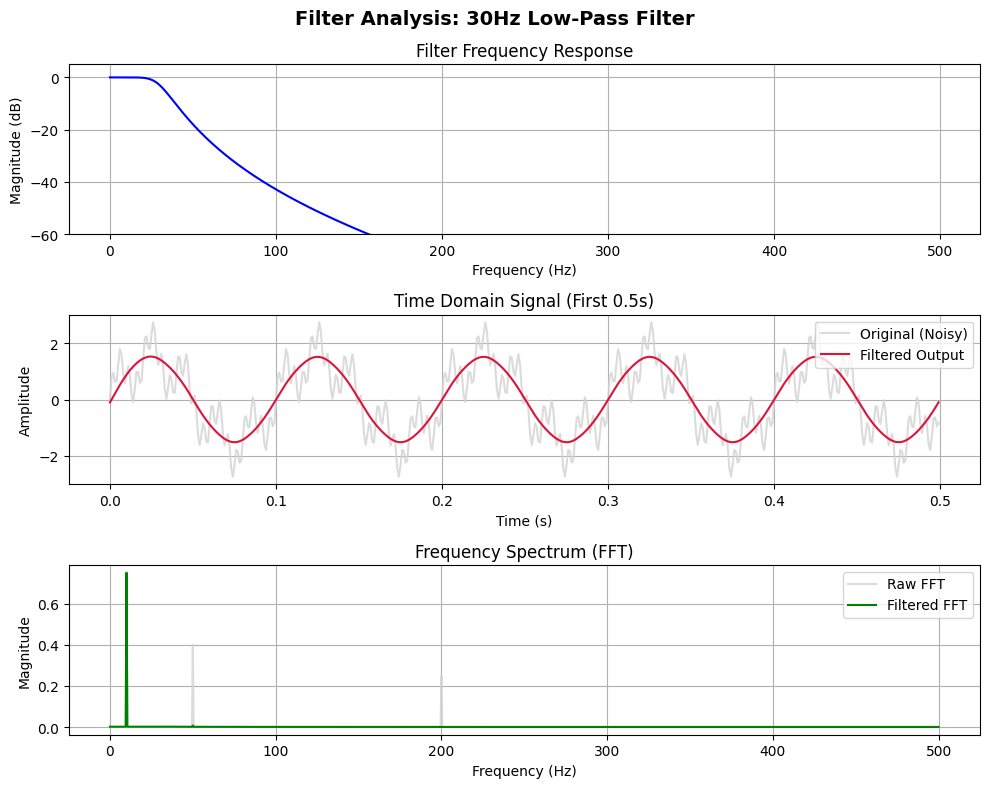

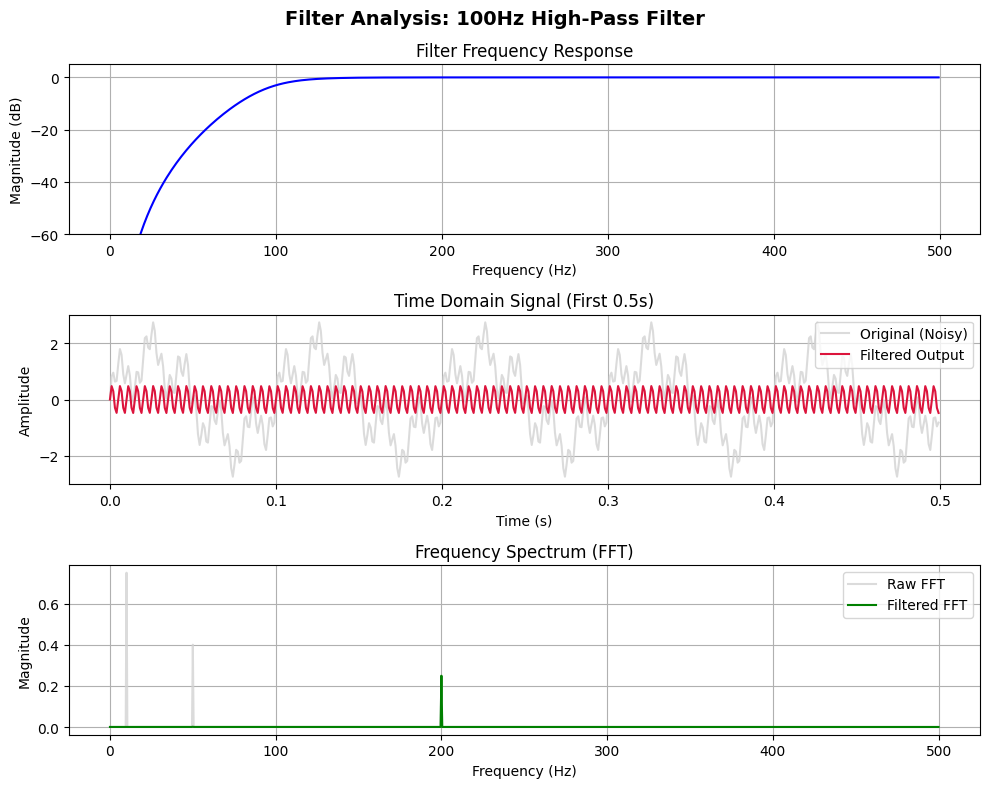

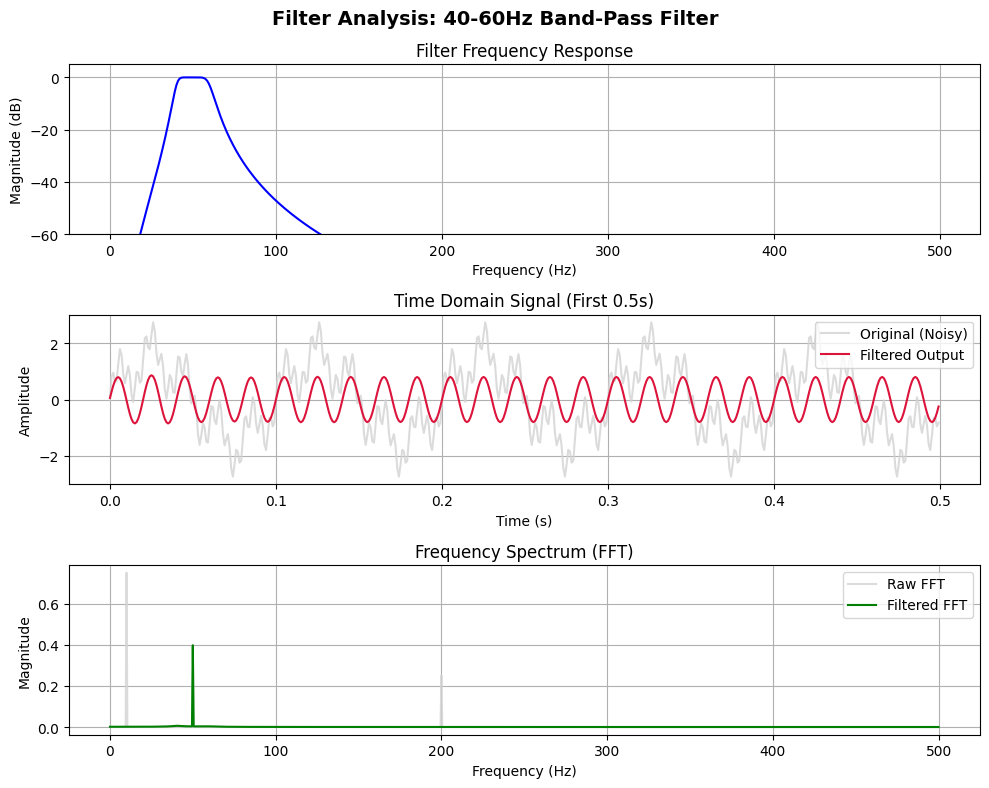

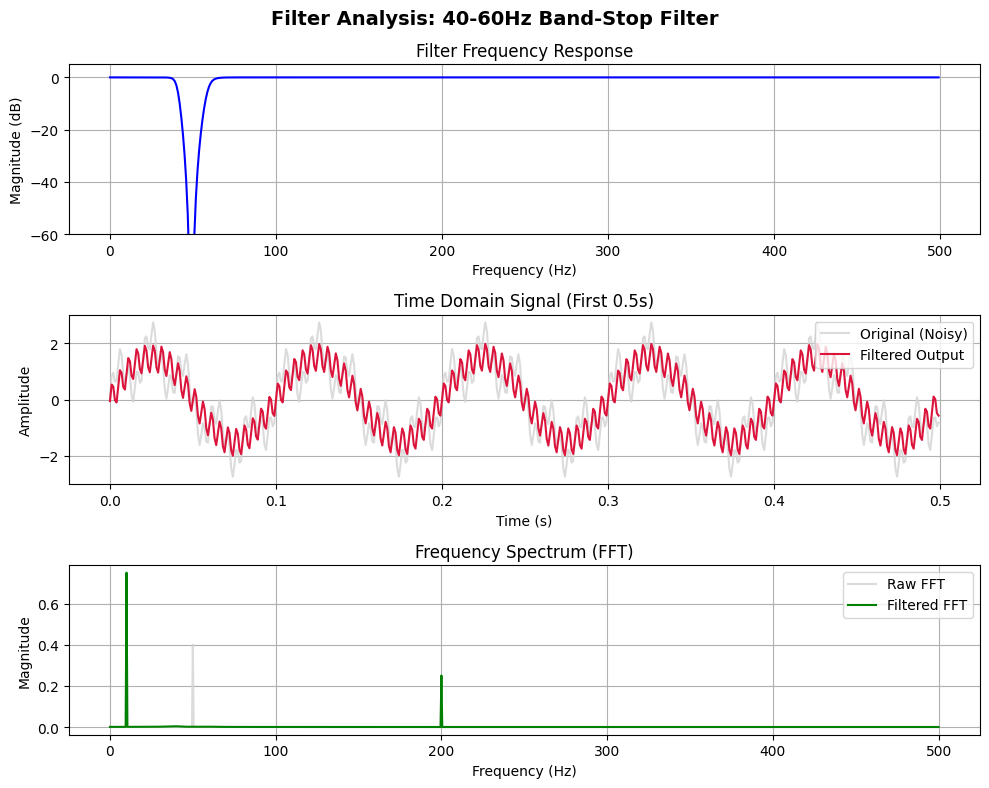

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, freqz, iirnotch

class DigitalFilterWorkbench:
    """
    A comprehensive DSP workbench for designing, applying, and analyzing
    digital filters (LPF, HPF, BPF, BSF, Notch).
    """
    def __init__(self, sampling_rate=1000.0):
        self.fs = sampling_rate  # Sampling frequency in Hz

    def _nyquist(self):
        return 0.5 * self.fs

    # 1. Low-Pass Filter
    def design_lowpass(self, cutoff_freq, order=4):
        nyq = self._nyquist()
        normal_cutoff = cutoff_freq / nyq
        b, a = butter(order, normal_cutoff, btype='low', analog=False)
        return b, a

    # 2. High-Pass Filter
    def design_highpass(self, cutoff_freq, order=4):
        nyq = self._nyquist()
        normal_cutoff = cutoff_freq / nyq
        b, a = butter(order, normal_cutoff, btype='high', analog=False)
        return b, a

    # 3. Band-Pass Filter
    def design_bandpass(self, low_cutoff, high_cutoff, order=4):
        nyq = self._nyquist()
        low = low_cutoff / nyq
        high = high_cutoff / nyq
        b, a = butter(order, [low, high], btype='bandpass', analog=False)
        return b, a

    # 4. Band-Stop Filter
    def design_bandstop(self, low_cutoff, high_cutoff, order=4):
        nyq = self._nyquist()
        low = low_cutoff / nyq
        high = high_cutoff / nyq
        b, a = butter(order, [low, high], btype='bandstop', analog=False)
        return b, a

    # 5. Notch Filter (Narrowband Rejection)
    def design_notch(self, notch_freq, quality_factor=30.0):
        b, a = iirnotch(w0=notch_freq, Q=quality_factor, fs=self.fs)
        return b, a

    # Zero-phase filtering to prevent phase distortion
    def apply_filter(self, b, a, data):
        return filtfilt(b, a, data)

    # Plotting helper for frequency response & time-domain signals
    def plot_analysis(self, time, raw_signal, filtered_signal, b, a, title_prefix):
        fig, axes = plt.subplots(3, 1, figsize=(10, 8))
        fig.suptitle(f'Filter Analysis: {title_prefix}', fontsize=14, fontweight='bold')

        # 1. Frequency Response Plot
        w, h = freqz(b, a, fs=self.fs)
        axes[0].plot(w, 20 * np.log10(abs(h)), 'b')
        axes[0].set_title('Filter Frequency Response')
        axes[0].set_xlabel('Frequency (Hz)')
        axes[0].set_ylabel('Magnitude (dB)')
        axes[0].grid(True)
        axes[0].set_ylim([-60, 5])

        # 2. Time Domain Comparison
        axes[1].plot(time[:500], raw_signal[:500], label='Original (Noisy)', color='lightgray', alpha=0.8)
        axes[1].plot(time[:500], filtered_signal[:500], label='Filtered Output', color='crimson')
        axes[1].set_title('Time Domain Signal (First 0.5s)')
        axes[1].set_xlabel('Time (s)')
        axes[1].set_ylabel('Amplitude')
        axes[1].legend(loc='upper right')
        axes[1].grid(True)

        # 3. Frequency Spectrum (FFT)
        n = len(raw_signal)
        fft_freqs = np.fft.rfftfreq(n, 1 / self.fs)
        fft_raw = np.abs(np.fft.rfft(raw_signal)) / n
        fft_filtered = np.abs(np.fft.rfft(filtered_signal)) / n

        axes[2].plot(fft_freqs, fft_raw, label='Raw FFT', color='lightgray', alpha=0.8)
        axes[2].plot(fft_freqs, fft_filtered, label='Filtered FFT', color='green')
        axes[2].set_title('Frequency Spectrum (FFT)')
        axes[2].set_xlabel('Frequency (Hz)')
        axes[2].set_ylabel('Magnitude')
        axes[2].legend(loc='upper right')
        axes[2].grid(True)

        plt.tight_layout()
        plt.show()


# --- Demonstration Run ---
if __name__ == '__main__':
    # 1. Generate Synthetic Signal (Composite Signal + Noise)
    sampling_rate = 1000.0  # 1 kHz sampling rate
    duration = 2.0          # 2 seconds
    t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)

    # Creating a signal with low (10 Hz), mid (50 Hz power line), and high (200 Hz) frequencies
    sig_10hz = 1.5 * np.sin(2 * np.pi * 10 * t)   # Desired low frequency
    sig_50hz = 0.8 * np.sin(2 * np.pi * 50 * t)   # Noise / Interference
    sig_200hz = 0.5 * np.sin(2 * np.pi * 200 * t) # High frequency noise

    synthetic_signal = sig_10hz + sig_50hz + sig_200hz

    # Initialize Workbench
    workbench = DigitalFilterWorkbench(sampling_rate=sampling_rate)

    # --- Demonstrate Notch Filter (Target 50 Hz Power Line Noise) ---
    b_notch, a_notch = workbench.design_notch(notch_freq=50.0, quality_factor=30.0)
    filtered_notch = workbench.apply_filter(b_notch, a_notch, synthetic_signal)
    workbench.plot_analysis(t, synthetic_signal, filtered_notch, b_notch, a_notch, "50Hz Notch Filter")

    # --- Demonstrate Low-Pass Filter (Cutoff at 30 Hz) ---
    b_lpf, a_lpf = workbench.design_lowpass(cutoff_freq=30.0, order=4)
    filtered_lpf = workbench.apply_filter(b_lpf, a_lpf, synthetic_signal)
    workbench.plot_analysis(t, synthetic_signal, filtered_lpf, b_lpf, a_lpf, "30Hz Low-Pass Filter")

    # --- Demonstrate High-Pass Filter (Cutoff at 100 Hz) ---
    b_hpf, a_hpf = workbench.design_highpass(cutoff_freq=100.0, order=4)
    filtered_hpf = workbench.apply_filter(b_hpf, a_hpf, synthetic_signal)
    workbench.plot_analysis(t, synthetic_signal, filtered_hpf, b_hpf, a_hpf, "100Hz High-Pass Filter")

    # --- Demonstrate Band-Pass Filter (Pass 40 Hz to 60 Hz) ---
    b_bpf, a_bpf = workbench.design_bandpass(low_cutoff=40.0, high_cutoff=60.0, order=4)
    filtered_bpf = workbench.apply_filter(b_bpf, a_bpf, synthetic_signal)
    workbench.plot_analysis(t, synthetic_signal, filtered_bpf, b_bpf, a_bpf, "40-60Hz Band-Pass Filter")

    # Band-Stop Filter (Stop 40 Hz to 60 Hz)
    b_bsf, a_bsf = workbench.design_bandstop(low_cutoff= 40.0, high_cutoff = 60.0, order=4)
    filtered_bsf = workbench.apply_filter(b_bsf, a_bsf, synthetic_signal)
    workbench.plot_analysis(t, synthetic_signal, filtered_bsf, b_bsf, a_bsf, '40-60Hz Band-Stop Filter')